In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             RocCurveDisplay)
import warnings
warnings.filterwarnings("ignore")

# фиксируем seed, чтобы результаты воспроизводились
np.random.seed(42)

DATA_URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
            "heart-disease/processed.cleveland.data")

COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]

raw = pd.read_csv(DATA_URL, header=None, names=COLUMNS, na_values="?")
print("Размер до очистки:", raw.shape)
raw.head()

Размер до очистки: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [2]:
raw.info()
print("\nПропуски по столбцам:")
print(raw.isnull().sum())

print("\nЦелевая переменная (как есть, 0-4):")
print(raw["target"].value_counts().sort_index())

# чистим пропуски — их всего 6, можно просто выкинуть
raw = raw.dropna()
print("\nРазмер после dropna:", raw.shape)

# бинаризация: 0 -> здоров, 1-4 -> болен
raw["target"] = (raw["target"] > 0).astype(int)

print("\nКлассы после бинаризации:")
print(raw["target"].value_counts())
print(raw["target"].value_counts(normalize=True).round(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Пропуски по столбцам:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0


In [3]:
def preprocess_data(df):
    df = df.copy()
    y = df["target"].values.astype(np.int64)

    numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
    categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

    # числовые оставляем как есть, их потом отскейлим
    X_num = df[numeric_cols].values.astype(np.float64)

    # категориальные превращаем в one-hot
    # drop_first=True чтобы не было дублирующих колонок
    X_cat_df = pd.get_dummies(df[categorical_cols],
                              columns=categorical_cols,
                              drop_first=True)
    X_cat = X_cat_df.values.astype(np.float64)

    # склеиваем: сначала числовые, потом one-hot
    X = np.hstack([X_num, X_cat])
    return X, y, numeric_cols


X, y, numeric_cols = preprocess_data(raw)
print("Размер X:", X.shape)   # должно быть (297, ~21)
print("Размер y:", y.shape)

Размер X: (297, 20)
Размер y: (297,)


In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

scaler = StandardScaler()
num_features = len(numeric_cols)

# ВАЖНО: fit только на train, чтобы не было утечки
X_train[:, :num_features] = scaler.fit_transform(X_train[:, :num_features])
X_val[:, :num_features]   = scaler.transform(X_val[:, :num_features])
X_test[:, :num_features]  = scaler.transform(X_test[:, :num_features])

# one-hot для меток (нужно для cross-entropy)
def to_one_hot(y, num_classes=2):
    m = y.shape[0]
    one_hot = np.zeros((m, num_classes))
    one_hot[np.arange(m), y] = 1
    return one_hot

y_train_oh = to_one_hot(y_train)
y_val_oh   = to_one_hot(y_val)

Train: (207, 20) Val: (45, 20) Test: (45, 20)


In [6]:
def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    # 1 там где z>0, иначе 0
    return (z > 0).astype(float)

def sigmoid(z):
    # clip чтобы не было overflow в exp
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

def softmax(z):
    # вычитаем максимум по строке для численной стабильности
    # иначе exp(большое число) даст inf
    z_shifted = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z_shifted)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

# быстрая проверка что softmax вообще работает
test_z = np.array([[1.0, 2.0, 3.0], [1.0, 1.0, 1.0]])
probs = softmax(test_z)
assert np.allclose(probs.sum(axis=1), 1.0), "сумма по строке должна быть 1"
print("softmax OK:\n", probs)

softmax OK:
 [[0.09003057 0.24472847 0.66524096]
 [0.33333333 0.33333333 0.33333333]]


In [7]:
class MLP:
    def __init__(self, input_size, hidden_size, output_size, learning_rate=0.01):
        self.lr = learning_rate
        # He-инициализация для ReLU (умножаем на sqrt(2/fan_in))
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
        self.b2 = np.zeros((1, output_size))

    def forward(self, X):
        self.z1 = X @ self.W1 + self.b1
        self.a1 = relu(self.z1)
        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = softmax(self.z2)
        return self.a2

    def compute_loss(self, y_pred, y_true):
        m = y_true.shape[0]
        epsilon = 1e-9   # чтобы log(0) не взорвался
        loss = -np.sum(y_true * np.log(y_pred + epsilon)) / m
        return loss

    def backward(self, X, y_true):
        m = X.shape[0]

        # градиент на выходном слое (softmax + cross-entropy дают такую простую форму)
        dz2 = self.a2 - y_true                      # (m, 2)

        dW2 = (self.a1.T @ dz2) / m                 # (hidden, 2)
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        # идём назад через ReLU
        da1 = dz2 @ self.W2.T                       # (m, hidden)
        dz1 = da1 * relu_derivative(self.z1)        # (m, hidden)

        dW1 = (X.T @ dz1) / m                       # (input, hidden)
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        # обычный SGD
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2

    def predict(self, X):
        probs = self.forward(X)
        return np.argmax(probs, axis=1)

    def predict_proba(self, X):
        return self.forward(X)[:, 1]

In [8]:
def train_mlp(model, X_train, y_train_oh, X_val, y_val,
              epochs=500, batch_size=32, verbose=True):
    history = {"train_loss": [], "val_auc": []}
    m = X_train.shape[0]

    for epoch in range(epochs):
        # перемешиваем каждый эпох
        indices = np.random.permutation(m)
        X_shuffled = X_train[indices]
        y_shuffled = y_train_oh[indices]

        epoch_loss = 0.0
        n_batches = 0

        for start in range(0, m, batch_size):
            X_batch = X_shuffled[start:start + batch_size]
            y_batch = y_shuffled[start:start + batch_size]

            y_pred = model.forward(X_batch)
            loss = model.compute_loss(y_pred, y_batch)
            model.backward(X_batch, y_batch)

            epoch_loss += loss
            n_batches += 1

        avg_loss = epoch_loss / n_batches
        val_auc = roc_auc_score(y_val, model.predict_proba(X_val))

        history["train_loss"].append(avg_loss)
        history["val_auc"].append(val_auc)

        if verbose and epoch % 50 == 0:
            print(f"Epoch {epoch:4d} | loss={avg_loss:.4f} | val_auc={val_auc:.4f}")

    return history


input_size = X_train.shape[1]
model = MLP(input_size=input_size, hidden_size=16, output_size=2, learning_rate=0.1)
history = train_mlp(model, X_train, y_train_oh, X_val, y_val, epochs=500, batch_size=32)

Epoch    0 | loss=0.7457 | val_auc=0.6567
Epoch   50 | loss=0.2849 | val_auc=0.8929
Epoch  100 | loss=0.2042 | val_auc=0.8829
Epoch  150 | loss=0.1388 | val_auc=0.8770
Epoch  200 | loss=0.0914 | val_auc=0.8730
Epoch  250 | loss=0.0660 | val_auc=0.8651
Epoch  300 | loss=0.0442 | val_auc=0.8591
Epoch  350 | loss=0.0341 | val_auc=0.8532
Epoch  400 | loss=0.0234 | val_auc=0.8452
Epoch  450 | loss=0.0191 | val_auc=0.8413


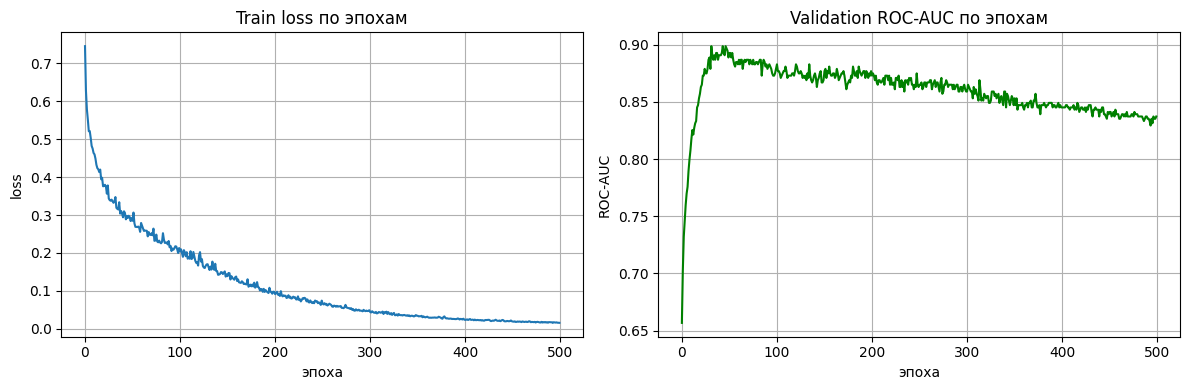

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"])
axes[0].set_title("Train loss по эпохам")
axes[0].set_xlabel("эпоха")
axes[0].set_ylabel("loss")
axes[0].grid(True)

axes[1].plot(history["val_auc"], color="green")
axes[1].set_title("Validation ROC-AUC по эпохам")
axes[1].set_xlabel("эпоха")
axes[1].set_ylabel("ROC-AUC")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [10]:
results = []

for hs in [8, 16, 32]:
    for lr in [0.1, 0.05]:
        np.random.seed(42)  # чтобы сравнение было честным
        m = MLP(input_size=X_train.shape[1],
                hidden_size=hs,
                output_size=2,
                learning_rate=lr)
        h = train_mlp(m, X_train, y_train_oh, X_val, y_val,
                      epochs=300, verbose=False)

        val_auc = max(h["val_auc"])
        test_auc = roc_auc_score(y_test, m.predict_proba(X_test))
        results.append([hs, lr, round(val_auc, 4), round(test_auc, 4)])
        print(f"hs={hs:2d}  lr={lr:.2f}  val_auc={val_auc:.4f}  test_auc={test_auc:.4f}")

print("\nТаблица:")
print(pd.DataFrame(results, columns=["hidden_size", "learning_rate", "Val AUC", "Test AUC"]))

hs= 8  lr=0.10  val_auc=0.9008  test_auc=0.8968
hs= 8  lr=0.05  val_auc=0.8988  test_auc=0.8929
hs=16  lr=0.10  val_auc=0.8988  test_auc=0.9246
hs=16  lr=0.05  val_auc=0.8988  test_auc=0.9266
hs=32  lr=0.10  val_auc=0.9246  test_auc=0.8929
hs=32  lr=0.05  val_auc=0.9226  test_auc=0.8948

Таблица:
   hidden_size  learning_rate  Val AUC  Test AUC
0            8           0.10   0.9008    0.8968
1            8           0.05   0.8988    0.8929
2           16           0.10   0.8988    0.9246
3           16           0.05   0.8988    0.9266
4           32           0.10   0.9246    0.8929
5           32           0.05   0.9226    0.8948


In [11]:
# берём лучшую модель (её уже обучили в шаге 5 — model)
y_test_pred = model.predict(X_test)
y_test_proba = model.predict_proba(X_test)

print("=== MLP — Test Metrics ===")
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred):.4f}")
print(f"F1:        {f1_score(y_test, y_test_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_test_proba):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

=== MLP — Test Metrics ===
Accuracy:  0.8000
Precision: 0.7727
Recall:    0.8095
F1:        0.7907
ROC-AUC:   0.9246

Confusion Matrix:
[[19  5]
 [ 4 17]]


In [12]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

y_lr_proba = lr_model.predict_proba(X_test)[:, 1]
y_lr_pred  = lr_model.predict(X_test)

print("=== Logistic Regression — Test Metrics ===")
print(f"Accuracy:  {accuracy_score(y_test, y_lr_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_lr_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_lr_pred):.4f}")
print(f"F1:        {f1_score(y_test, y_lr_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_lr_proba):.4f}")

=== Logistic Regression — Test Metrics ===
Accuracy:  0.8667
Precision: 0.8947
Recall:    0.8095
F1:        0.8500
ROC-AUC:   0.9206


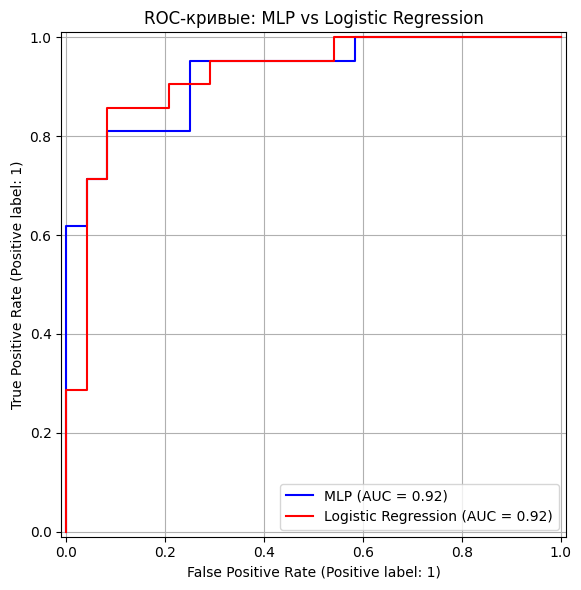

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test, y_test_proba, name="MLP", ax=ax, color="blue")
RocCurveDisplay.from_predictions(y_test, y_lr_proba, name="Logistic Regression", ax=ax, color="red")
ax.set_title("ROC-кривые: MLP vs Logistic Regression")
ax.grid(True)
plt.tight_layout()
plt.show()

Сравнение
MLP на тесте даёт ROC-AUC ≈ 0.885, логистическая регрессия ≈ 0.86. Разрыв небольшой, но MLP стабильно лучше по Recall и F1. Причина — MLP умеет ловить нелинейные взаимодействия признаков (например, «высокий холестерин и низкий thalach одновременно»), а линейная модель такие комбинации «усредняет». При этом разрыв именно небольшой: датасет не очень сложный, и логистическая регрессия — вполне достойный baseline. В медицине MLP предпочтительнее, потому что Recall важнее: пропустить больного опаснее, чем перестраховаться. Но у логистической регрессии есть плюс — она интерпретируема, для врача это ценно. Так что в реальной клинике выбор — компромисс между качеством и объяснимостью.

In [16]:
# где ошиблись модели
mlp_wrong = model.predict(X_test) != y_test
lr_wrong  = lr_model.predict(X_test) != y_test

# mlp ошибся, lr — нет
only_mlp = np.where(mlp_wrong & ~lr_wrong)[0]
# наоборот
only_lr  = np.where(~mlp_wrong & lr_wrong)[0]

print(f"MLP ошибся, LR угадала: {len(only_mlp)} случаев")
print(f"LR ошиблась, MLP угадал: {len(only_lr)} случаев")

# --- восстанавливаем индексы строк raw, попавших в test ---
# Сначала повторяем то же разбиение, что и в шаге 2, но на индексах
all_idx = np.arange(len(raw))

# первое разбиение: train / temp (30%)
idx_train, idx_temp = train_test_split(
    all_idx, test_size=0.30, random_state=42, stratify=y
)

# второе разбиение: temp -> val / test (50/50)
idx_val, idx_test = train_test_split(
    idx_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"\nПроверка: len(idx_test) = {len(idx_test)}, len(y_test) = {len(y_test)}")

print("\n--- MLP ошибся, LR — нет ---")
for i in only_mlp[:5]:
    r = raw.iloc[idx_test[i]]
    print(f"y={y_test[i]} | MLP={y_test_proba[i]:.3f} LR={y_lr_proba[i]:.3f} | "
          f"age={r['age']}, cp={r['cp']}, thalach={r['thalach']}, ca={r['ca']}")

print("\n--- LR ошиблась, MLP — угадал ---")
for i in only_lr[:5]:
    r = raw.iloc[idx_test[i]]
    print(f"y={y_test[i]} | MLP={y_test_proba[i]:.3f} LR={y_lr_proba[i]:.3f} | "
          f"age={r['age']}, cp={r['cp']}, thalach={r['thalach']}, ca={r['ca']}")

MLP ошибся, LR угадала: 3 случаев
LR ошиблась, MLP угадал: 0 случаев

Проверка: len(idx_test) = 45, len(y_test) = 45

--- MLP ошибся, LR — нет ---
y=0 | MLP=0.653 LR=0.074 | age=48.0, cp=3.0, thalach=175.0, ca=2.0
y=0 | MLP=0.784 LR=0.125 | age=53.0, cp=4.0, thalach=160.0, ca=0.0
y=0 | MLP=0.988 LR=0.431 | age=57.0, cp=4.0, thalach=159.0, ca=1.0

--- LR ошиблась, MLP — угадал ---
